## LaDe 24: Bridge Tunnel Movement (Flag 24)

### Dataset Overview

Constructed LaDe-style courier data on archived Shanghai WGS84 OSM roads. Task IDs, schedules, movement speeds, delivery windows, AOIs and regions are synthetic extensions, not original LaDe observations. Native fclass, oneway, bridge and tunnel attributes are copied from OSM; absence of a tag is encoded no, not independent confirmation that a structure is absent. GPS retains all road vertices; spatial spacing is at most 22 m, stationary intervals at most 55 s. Each travelling row and its road_segment_id describe the immediately preceding GPS interval; stationary rows have no road attribution. Speed is distance divided by time, excluding service/waiting. Route directness ratio means travelled distance divided by straight-line task-endpoint distance. One-way share is distance weighted (0–1), not percent. Movement phases label ordered workday route periods, not fixed clock bins. Directions are checked but OSM turn restrictions are not modeled. Tunnel coordinates are constructed map interpolation, not authentic underground GPS fixes. All times are local Shanghai time. Pending tasks intentionally have no completion time or arrival leg; other task completions coincide with stationary GPS fixes. Service visits are recorded intervals at roadside task sites, not official AOI boundaries. Repositioning and return legs remain visible but are excluded where an insight concerns task-to-task legs. Approach class is the distance-dominant fclass in the final 800 m before the structure, not necessarily the immediately adjoining edge.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Investigate courier movement dynamics under different road-network conditions.

Role: Last-mile logistics analyst


Category: bridge_tunnel_movement


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What CSV-derived evidence supports insight 1?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

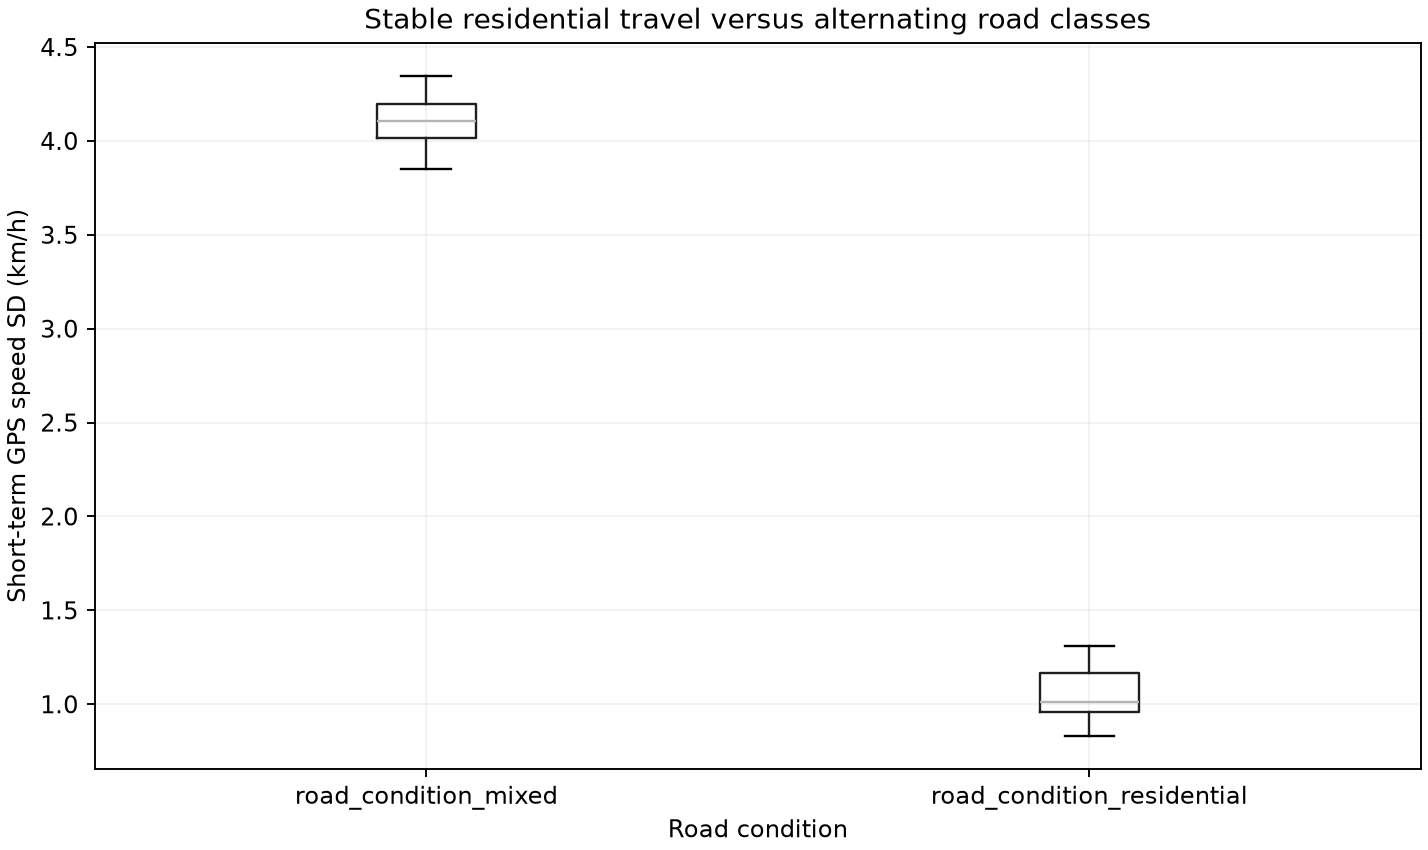

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["crossings"] = pd.read_csv("crossings.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            stamp = pd.to_datetime(q.departure_time, format="mixed")
            q["departure_hour"] = (
                stamp - stamp.dt.normalize()
            ).dt.total_seconds() / 3600
            centers = np.arange(
                np.floor(q.departure_hour.min() * 6) / 6,
                np.ceil(q.departure_hour.max() * 6) / 6 + 1 / 12,
                1 / 6,
            )
            windows = []
            for center in centers:
                subset = q[q.departure_hour.between(center - 0.5, center + 0.5)]
                windows.append(
                    {
                        "center_hour": float(center),
                        "legs": len(subset),
                        **{
                            column: (
                                float(subset[column].median())
                                if len(subset) >= 8
                                else None
                            )
                            for column in ["mean_speed_kmh", "route_directness_ratio"]
                        },
                    }
                )
            trend = pd.DataFrame(windows)
            plt.close(fig)
            fig, axes = plt.subplots(
                2, 1, figsize=(9.5, 7), sharex=True, constrained_layout=True
            )
            fig.suptitle("Speed and detour over actual departure time", fontsize=15)
            for axis, column, color, title in [
                (
                    axes[0],
                    "mean_speed_kmh",
                    "#3976a8",
                    "Movement speed of each task-to-task leg",
                ),
                (
                    axes[1],
                    "route_directness_ratio",
                    "#c77c3d",
                    "Route detour of the same legs at the same times",
                ),
            ]:
                normal = q[q.period.ne("exception")]
                exception = q[q.period.eq("exception")]
                axis.scatter(
                    normal.departure_hour,
                    normal[column],
                    s=22,
                    color=color,
                    alpha=0.45,
                    label=f"Task-to-task legs ({len(normal)}; 14 days)",
                )
                axis.scatter(
                    exception.departure_hour,
                    exception[column],
                    s=110,
                    color="#8c405f",
                    marker="*",
                    label="Exceptional leg (insight 4)",
                    zorder=4,
                )
                axis.plot(
                    trend.center_hour,
                    trend[column],
                    color=color,
                    linewidth=2.5,
                    label="60-min rolling median (≥8 legs)",
                )
                axis.set_title(title, fontsize=11)
                axis.grid(axis="y", alpha=0.15)
                axis.margins(x=0.03, y=0.30)
                axis.legend(loc="upper left", fontsize=8, frameon=False)
            axes[0].set_ylabel("Mean movement speed (km/h)")
            axes[1].set_ylabel(
                "Travelled / straight-line distance\nHigher = more detour"
            )
            ticks = np.arange(
                np.floor(q.departure_hour.min()), np.ceil(q.departure_hour.max()) + 1
            )
            axes[1].set(
                xticks=ticks,
                xticklabels=[f"{int(h):02}:00" for h in ticks],
                xlabel="Actual leg departure time (Shanghai local time; days overlaid)",
            )
            value = {
                "period_means": means.to_dict("index"),
                "period_means_note": (
                    "Legacy phase aggregates retained for compatibility; not used to"
                    " draw this chart."
                ),
                "plotted_task_to_task_legs": len(q),
                "exception_legs_included": int(q.period.eq("exception").sum()),
                "rolling_window_minutes": 60,
                "minimum_legs_per_window": 8,
                "clock_time_rolling_medians": [
                    window for window in windows if window["legs"] >= 8
                ],
                "omitted_window_centers_hour": [
                    window["center_hour"] for window in windows if window["legs"] < 8
                ],
            }
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                # Fluctuation is within-crossing GPS speed SD, not variation
                # between the average speeds of different crossings.
                recomputed = moving.groupby("leg_id").speed_kmh.agg(
                    lambda s: float(np.std(s.to_numpy(), ddof=0))
                )
                np.testing.assert_allclose(
                    q.speed_std_kmh, q.leg_id.map(recomputed), atol=1e-8
                )
                plt.close(fig)
                fig, axes = plt.subplots(
                    1, 2, figsize=(12.5, 5.5), constrained_layout=True
                )
                ax = axes[0]
                structures = (
                    q[["structure_osm_way_id", "structure_type"]]
                    .drop_duplicates()
                    .sort_values("structure_type")
                )
                ticks = []
                labels = []
                for axis, column, title, ylabel in [
                    (
                        axes[0],
                        "low_speed_seconds",
                        "Longer low-speed time later in the workday",
                        "Time below 12 km/h per crossing (seconds)",
                    ),
                    (
                        axes[1],
                        "speed_std_kmh",
                        "Greater speed fluctuations later in the workday",
                        "Within-crossing GPS speed SD (km/h)",
                    ),
                ]:
                    for i, structure in enumerate(structures.itertuples()):
                        group = q[
                            q.structure_osm_way_id.eq(structure.structure_osm_way_id)
                        ]
                        paired = group.pivot(
                            index=["service_date", "approach_fclass"],
                            columns="period",
                            values=column,
                        )
                        assert paired[["early", "late"]].notna().all().all()
                        for row in paired.itertuples():
                            axis.plot(
                                [i * 3, i * 3 + 1],
                                [row.early, row.late],
                                color="#aab4bc",
                                alpha=0.5,
                                linewidth=0.8,
                            )
                        for j, (period, color) in enumerate(
                            [("early", "#3976a8"), ("late", "#c77c3d")]
                        ):
                            values = group.loc[group.period.eq(period), column]
                            axis.scatter(
                                np.full(len(values), i * 3 + j),
                                values,
                                s=24,
                                color=color,
                                alpha=0.7,
                                label=(
                                    period.capitalize() + " crossing"
                                    if i == 0
                                    else None
                                ),
                                zorder=3,
                            )
                            mean = values.mean()
                            axis.plot(
                                [i * 3 + j - 0.18, i * 3 + j + 0.18],
                                [mean, mean],
                                color="black",
                                linewidth=2,
                                label="Group mean" if i == 0 and j == 0 else None,
                                zorder=4,
                            )
                            axis.annotate(
                                f"{mean:.2f}",
                                (i * 3 + j, values.max()),
                                xytext=(0, 10),
                                textcoords="offset points",
                                ha="center",
                                fontweight="bold",
                                fontsize=10,
                            )
                        if axis is axes[0]:
                            ticks.extend([i * 3, i * 3 + 1])
                            labels.extend(
                                [
                                    f"Early\n{structure.structure_type.title()}",
                                    f"Late\n{structure.structure_type.title()}",
                                ]
                            )
                    axis.set(
                        xticks=ticks,
                        xticklabels=labels,
                        ylabel=ylabel,
                        title=title,
                        xlabel=(
                            "Paired within the same day, structure and approach class"
                        ),
                    )
                    axis.set_ylim(
                        0,
                        (
                            group[column].max() * 1.5
                            if column == "speed_std_kmh"
                            else q[column].max() * 1.5
                        ),
                    )
                    axis.legend(loc="upper left", fontsize=8, frameon=False)
                    axis.grid(axis="y", alpha=0.15)
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(24, 1, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_1",
  "insight_type": "overall_pattern",
  "insight": "Movement on residential roads shows more stable speeds, while segments alternating between tertiary and residential roads exhibit larger short-term speed fluctuations.",
  "insight_value": {
    "condition_means": {
      "road_condition_mixed": {
        "speed_std_kmh": 4.1047375407348365,
        "residential_share": 0.46226676352063867,
        "tertiary_share": 0.48390085546413447,
        "fclass_transitions": 3.25
      },
      "road_condition_residential": {
        "speed_std_kmh": 1.0574251723374326,
        "residential_share": 0.970963810380781,
        "tertiary_share": 0.0,
        "fclass_transitions": 0.625
      }
    }
  },
  "question": "What CSV-derived evidence supports insight 1?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 24 insight 1",
    "file": "visualizations/insight_1.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"crossings\"] = pd.read_csv(\"crossings.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            stamp=pd.to_datetime(q.departure_time,format='mixed')\n            q['departure_hour']=(stamp-stamp.dt.normalize()).dt.total_seconds()/3600\n            centers=np.arange(np.floor(q.departure_hour.min()*6)/6,np.ceil(q.departure_hour.max()*6)/6+1/12,1/6)\n            windows=[]\n            for center in centers:\n                subset=q[q.departure_hour.between(center-.5,center+.5)]\n                windows.append({'center_hour':float(center),'legs':len(subset),\n                    **{column:float(subset[column].median()) if len(subset)>=8 else None\n                       for column in ['mean_speed_kmh','route_directness_ratio']}})\n            trend=pd.DataFrame(windows)\n            plt.close(fig)\n            fig,axes=plt.subplots(2,1,figsize=(9.5,7),sharex=True,constrained_layout=True)\n            fig.suptitle('Speed and detour over actual departure time',fontsize=15)\n            for axis,column,color,title in [\n                (axes[0],'mean_speed_kmh','#3976a8','Movement speed of each task-to-task leg'),\n                (axes[1],'route_directness_ratio','#c77c3d','Route detour of the same legs at the same times')]:\n                normal=q[q.period.ne('exception')];exception=q[q.period.eq('exception')]\n                axis.scatter(normal.departure_hour,normal[column],s=22,color=color,alpha=.45,\n                    label=f'Task-to-task legs ({len(normal)}; 14 days)')\n                axis.scatter(exception.departure_hour,exception[column],s=110,color='#8c405f',marker='*',\n                    label='Exceptional leg (insight 4)',zorder=4)\n                axis.plot(trend.center_hour,trend[column],color=color,linewidth=2.5,\n                    label='60-min rolling median (≥8 legs)')\n                axis.set_title(title,fontsize=11)\n                axis.grid(axis='y',alpha=.15)\n                axis.margins(x=.03,y=.30)\n                axis.legend(loc='upper left',fontsize=8,frameon=False)\n            axes[0].set_ylabel('Mean movement speed (km/h)')\n            axes[1].set_ylabel('Travelled / straight-line distance\\nHigher = more detour')\n            ticks=np.arange(np.floor(q.departure_hour.min()),np.ceil(q.departure_hour.max())+1)\n            axes[1].set(xticks=ticks,xticklabels=[f'{int(h):02}:00' for h in ticks],\n                xlabel='Actual leg departure time (Shanghai local time; days overlaid)')\n            value = {'period_means': means.to_dict('index'),\n                'period_means_note':'Legacy phase aggregates retained for compatibility; not used to draw this chart.',\n                'plotted_task_to_task_legs':len(q),'exception_legs_included':int(q.period.eq('exception').sum()),\n                'rolling_window_minutes':60,'minimum_legs_per_window':8,\n                'clock_time_rolling_medians':[window for window in windows if window['legs']>=8],\n                'omitted_window_centers_hour':[window['center_hour'] for window in windows if window['legs']<8]}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                # Fluctuation is within-crossing GPS speed SD, not variation\n                # between the average speeds of different crossings.\n                recomputed=moving.groupby('leg_id').speed_kmh.agg(lambda s:float(np.std(s.to_numpy(),ddof=0)))\n                np.testing.assert_allclose(q.speed_std_kmh,q.leg_id.map(recomputed),atol=1e-8)\n                plt.close(fig)\n                fig,axes=plt.subplots(1,2,figsize=(12.5,5.5),constrained_layout=True);ax=axes[0]\n                structures=q[['structure_osm_way_id','structure_type']].drop_duplicates().sort_values('structure_type')\n                ticks=[];labels=[]\n                for axis,column,title,ylabel in [\n                    (axes[0],'low_speed_seconds','Longer low-speed time later in the workday','Time below 12 km/h per crossing (seconds)'),\n                    (axes[1],'speed_std_kmh','Greater speed fluctuations later in the workday','Within-crossing GPS speed SD (km/h)')]:\n                    for i,structure in enumerate(structures.itertuples()):\n                        group=q[q.structure_osm_way_id.eq(structure.structure_osm_way_id)]\n                        paired=group.pivot(index=['service_date','approach_fclass'],columns='period',values=column)\n                        assert paired[['early','late']].notna().all().all()\n                        for row in paired.itertuples():\n                            axis.plot([i*3,i*3+1],[row.early,row.late],color='#aab4bc',alpha=.5,linewidth=.8)\n                        for j,(period,color) in enumerate([('early','#3976a8'),('late','#c77c3d')]):\n                            values=group.loc[group.period.eq(period),column]\n                            axis.scatter(np.full(len(values),i*3+j),values,s=24,color=color,alpha=.7,\n                                label=period.capitalize()+' crossing' if i==0 else None,zorder=3)\n                            mean=values.mean()\n                            axis.plot([i*3+j-.18,i*3+j+.18],[mean,mean],color='black',linewidth=2,\n                                label='Group mean' if i==0 and j==0 else None,zorder=4)\n                            axis.annotate(f'{mean:.2f}',(i*3+j,values.max()),xytext=(0,10),textcoords='offset points',\n                                ha='center',fontweight='bold',fontsize=10)\n                        if axis is axes[0]:\n                            ticks.extend([i*3,i*3+1]);labels.extend([f'Early\\n{structure.structure_type.title()}',f'Late\\n{structure.structure_type.title()}'])\n                    axis.set(xticks=ticks,xticklabels=labels,ylabel=ylabel,title=title,\n                        xlabel='Paired within the same day, structure and approach class')\n                    axis.set_ylim(0,group[column].max()*1.5 if column=='speed_std_kmh' else q[column].max()*1.5)\n                    axis.legend(loc='upper left',fontsize=8,frameon=False)\n                    axis.grid(axis='y',alpha=.15)\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(24, 1, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "fclass",
    "gps_time",
    "gps_position",
    "movement_leg_id"
  ]
}

### **Question 2**: Do paired late crossings of the same structure have longer low-speed time and greater within-crossing speed variability?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

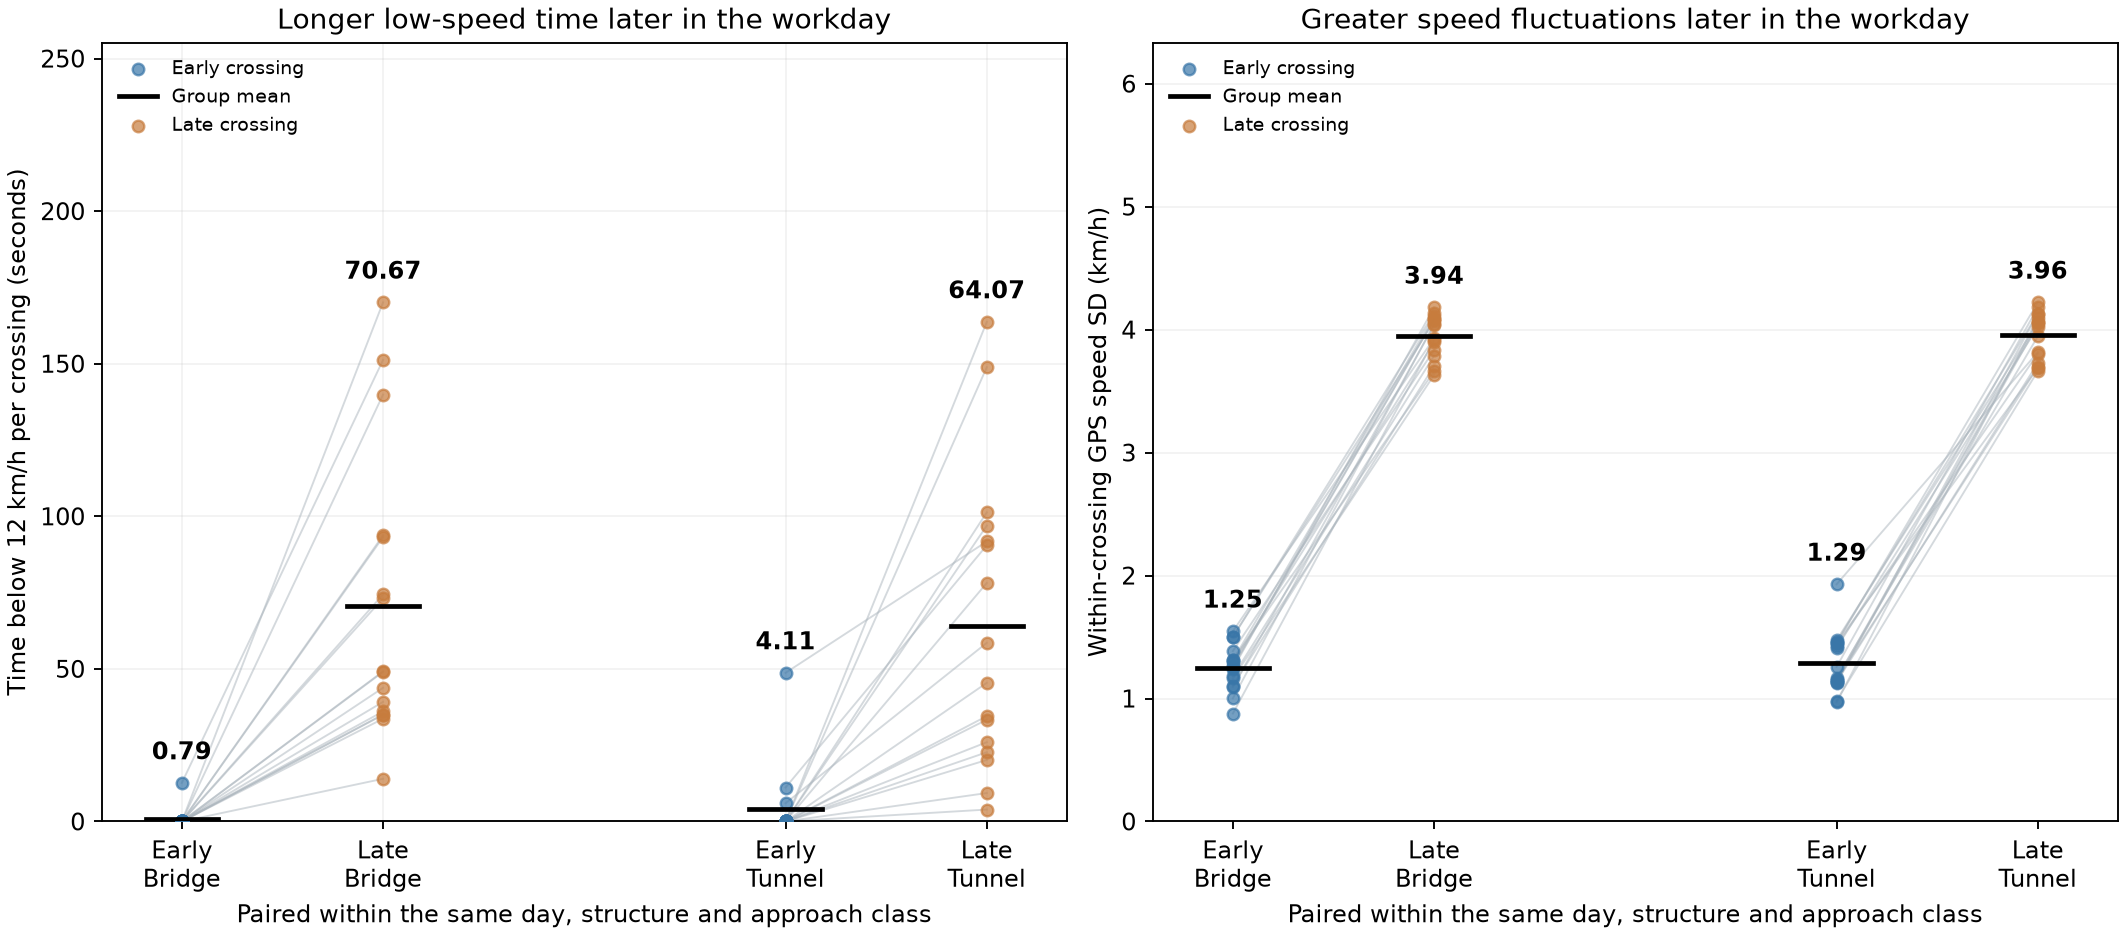

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["crossings"] = pd.read_csv("crossings.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            stamp = pd.to_datetime(q.departure_time, format="mixed")
            q["departure_hour"] = (
                stamp - stamp.dt.normalize()
            ).dt.total_seconds() / 3600
            centers = np.arange(
                np.floor(q.departure_hour.min() * 6) / 6,
                np.ceil(q.departure_hour.max() * 6) / 6 + 1 / 12,
                1 / 6,
            )
            windows = []
            for center in centers:
                subset = q[q.departure_hour.between(center - 0.5, center + 0.5)]
                windows.append(
                    {
                        "center_hour": float(center),
                        "legs": len(subset),
                        **{
                            column: (
                                float(subset[column].median())
                                if len(subset) >= 8
                                else None
                            )
                            for column in ["mean_speed_kmh", "route_directness_ratio"]
                        },
                    }
                )
            trend = pd.DataFrame(windows)
            plt.close(fig)
            fig, axes = plt.subplots(
                2, 1, figsize=(9.5, 7), sharex=True, constrained_layout=True
            )
            fig.suptitle("Speed and detour over actual departure time", fontsize=15)
            for axis, column, color, title in [
                (
                    axes[0],
                    "mean_speed_kmh",
                    "#3976a8",
                    "Movement speed of each task-to-task leg",
                ),
                (
                    axes[1],
                    "route_directness_ratio",
                    "#c77c3d",
                    "Route detour of the same legs at the same times",
                ),
            ]:
                normal = q[q.period.ne("exception")]
                exception = q[q.period.eq("exception")]
                axis.scatter(
                    normal.departure_hour,
                    normal[column],
                    s=22,
                    color=color,
                    alpha=0.45,
                    label=f"Task-to-task legs ({len(normal)}; 14 days)",
                )
                axis.scatter(
                    exception.departure_hour,
                    exception[column],
                    s=110,
                    color="#8c405f",
                    marker="*",
                    label="Exceptional leg (insight 4)",
                    zorder=4,
                )
                axis.plot(
                    trend.center_hour,
                    trend[column],
                    color=color,
                    linewidth=2.5,
                    label="60-min rolling median (≥8 legs)",
                )
                axis.set_title(title, fontsize=11)
                axis.grid(axis="y", alpha=0.15)
                axis.margins(x=0.03, y=0.30)
                axis.legend(loc="upper left", fontsize=8, frameon=False)
            axes[0].set_ylabel("Mean movement speed (km/h)")
            axes[1].set_ylabel(
                "Travelled / straight-line distance\nHigher = more detour"
            )
            ticks = np.arange(
                np.floor(q.departure_hour.min()), np.ceil(q.departure_hour.max()) + 1
            )
            axes[1].set(
                xticks=ticks,
                xticklabels=[f"{int(h):02}:00" for h in ticks],
                xlabel="Actual leg departure time (Shanghai local time; days overlaid)",
            )
            value = {
                "period_means": means.to_dict("index"),
                "period_means_note": (
                    "Legacy phase aggregates retained for compatibility; not used to"
                    " draw this chart."
                ),
                "plotted_task_to_task_legs": len(q),
                "exception_legs_included": int(q.period.eq("exception").sum()),
                "rolling_window_minutes": 60,
                "minimum_legs_per_window": 8,
                "clock_time_rolling_medians": [
                    window for window in windows if window["legs"] >= 8
                ],
                "omitted_window_centers_hour": [
                    window["center_hour"] for window in windows if window["legs"] < 8
                ],
            }
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                # Fluctuation is within-crossing GPS speed SD, not variation
                # between the average speeds of different crossings.
                recomputed = moving.groupby("leg_id").speed_kmh.agg(
                    lambda s: float(np.std(s.to_numpy(), ddof=0))
                )
                np.testing.assert_allclose(
                    q.speed_std_kmh, q.leg_id.map(recomputed), atol=1e-8
                )
                plt.close(fig)
                fig, axes = plt.subplots(
                    1, 2, figsize=(12.5, 5.5), constrained_layout=True
                )
                ax = axes[0]
                structures = (
                    q[["structure_osm_way_id", "structure_type"]]
                    .drop_duplicates()
                    .sort_values("structure_type")
                )
                ticks = []
                labels = []
                for axis, column, title, ylabel in [
                    (
                        axes[0],
                        "low_speed_seconds",
                        "Longer low-speed time later in the workday",
                        "Time below 12 km/h per crossing (seconds)",
                    ),
                    (
                        axes[1],
                        "speed_std_kmh",
                        "Greater speed fluctuations later in the workday",
                        "Within-crossing GPS speed SD (km/h)",
                    ),
                ]:
                    for i, structure in enumerate(structures.itertuples()):
                        group = q[
                            q.structure_osm_way_id.eq(structure.structure_osm_way_id)
                        ]
                        paired = group.pivot(
                            index=["service_date", "approach_fclass"],
                            columns="period",
                            values=column,
                        )
                        assert paired[["early", "late"]].notna().all().all()
                        for row in paired.itertuples():
                            axis.plot(
                                [i * 3, i * 3 + 1],
                                [row.early, row.late],
                                color="#aab4bc",
                                alpha=0.5,
                                linewidth=0.8,
                            )
                        for j, (period, color) in enumerate(
                            [("early", "#3976a8"), ("late", "#c77c3d")]
                        ):
                            values = group.loc[group.period.eq(period), column]
                            axis.scatter(
                                np.full(len(values), i * 3 + j),
                                values,
                                s=24,
                                color=color,
                                alpha=0.7,
                                label=(
                                    period.capitalize() + " crossing"
                                    if i == 0
                                    else None
                                ),
                                zorder=3,
                            )
                            mean = values.mean()
                            axis.plot(
                                [i * 3 + j - 0.18, i * 3 + j + 0.18],
                                [mean, mean],
                                color="black",
                                linewidth=2,
                                label="Group mean" if i == 0 and j == 0 else None,
                                zorder=4,
                            )
                            axis.annotate(
                                f"{mean:.2f}",
                                (i * 3 + j, values.max()),
                                xytext=(0, 10),
                                textcoords="offset points",
                                ha="center",
                                fontweight="bold",
                                fontsize=10,
                            )
                        if axis is axes[0]:
                            ticks.extend([i * 3, i * 3 + 1])
                            labels.extend(
                                [
                                    f"Early\n{structure.structure_type.title()}",
                                    f"Late\n{structure.structure_type.title()}",
                                ]
                            )
                    axis.set(
                        xticks=ticks,
                        xticklabels=labels,
                        ylabel=ylabel,
                        title=title,
                        xlabel=(
                            "Paired within the same day, structure and approach class"
                        ),
                    )
                    axis.set_ylim(
                        0,
                        (
                            group[column].max() * 1.5
                            if column == "speed_std_kmh"
                            else q[column].max() * 1.5
                        ),
                    )
                    axis.legend(loc="upper left", fontsize=8, frameon=False)
                    axis.grid(axis="y", alpha=0.15)
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(24, 2, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_2",
  "insight_type": "temporal_dynamics",
  "insight": "Repeated crossings of the same bridge or tunnel show longer low-speed periods and greater speed fluctuations later in the workday.",
  "insight_value": {
    "structure_period_means": [
      {
        "structure_osm_way_id": 50832813,
        "structure_type": "bridge",
        "period": "early",
        "low_speed_seconds": 0.789639689625,
        "speed_std_kmh": 1.2518389010228697,
        "mean_speed_kmh": 17.29143454630296
      },
      {
        "structure_osm_way_id": 50832813,
        "structure_type": "bridge",
        "period": "late",
        "low_speed_seconds": 70.6683554235625,
        "speed_std_kmh": 3.9443083473584144,
        "mean_speed_kmh": 10.484286918972991
      },
      {
        "structure_osm_way_id": 175468780,
        "structure_type": "tunnel",
        "period": "early",
        "low_speed_seconds": 4.1109318236875,
        "speed_std_kmh": 1.292357320368957,
        "mean_speed_kmh": 17.113918229037644
      },
      {
        "structure_osm_way_id": 175468780,
        "structure_type": "tunnel",
        "period": "late",
        "low_speed_seconds": 64.0688733523125,
        "speed_std_kmh": 3.9552938855987487,
        "mean_speed_kmh": 11.807199593208374
      }
    ],
    "crossings": 64,
    "unique_structures": 2
  },
  "question": "Do paired late crossings of the same structure have longer low-speed time and greater within-crossing speed variability?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "paired_low_speed_duration_and_speed_variability",
    "title": "LaDe 24 insight 2",
    "file": "visualizations/insight_2.png",
    "description": "Left: seconds below 12 km/h per crossing. Right: population standard deviation of the moving GPS interval speeds within each crossing, independently checked against GPS data. Dots show all 64 crossings; gray lines pair early/late crossings on the same day, same OSM structure and same approach road class. Black ticks and numeric labels show group means. Bridge and tunnel remain separate. This is within-crossing fluctuation, not dispersion of crossing mean speeds."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"crossings\"] = pd.read_csv(\"crossings.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            stamp=pd.to_datetime(q.departure_time,format='mixed')\n            q['departure_hour']=(stamp-stamp.dt.normalize()).dt.total_seconds()/3600\n            centers=np.arange(np.floor(q.departure_hour.min()*6)/6,np.ceil(q.departure_hour.max()*6)/6+1/12,1/6)\n            windows=[]\n            for center in centers:\n                subset=q[q.departure_hour.between(center-.5,center+.5)]\n                windows.append({'center_hour':float(center),'legs':len(subset),\n                    **{column:float(subset[column].median()) if len(subset)>=8 else None\n                       for column in ['mean_speed_kmh','route_directness_ratio']}})\n            trend=pd.DataFrame(windows)\n            plt.close(fig)\n            fig,axes=plt.subplots(2,1,figsize=(9.5,7),sharex=True,constrained_layout=True)\n            fig.suptitle('Speed and detour over actual departure time',fontsize=15)\n            for axis,column,color,title in [\n                (axes[0],'mean_speed_kmh','#3976a8','Movement speed of each task-to-task leg'),\n                (axes[1],'route_directness_ratio','#c77c3d','Route detour of the same legs at the same times')]:\n                normal=q[q.period.ne('exception')];exception=q[q.period.eq('exception')]\n                axis.scatter(normal.departure_hour,normal[column],s=22,color=color,alpha=.45,\n                    label=f'Task-to-task legs ({len(normal)}; 14 days)')\n                axis.scatter(exception.departure_hour,exception[column],s=110,color='#8c405f',marker='*',\n                    label='Exceptional leg (insight 4)',zorder=4)\n                axis.plot(trend.center_hour,trend[column],color=color,linewidth=2.5,\n                    label='60-min rolling median (≥8 legs)')\n                axis.set_title(title,fontsize=11)\n                axis.grid(axis='y',alpha=.15)\n                axis.margins(x=.03,y=.30)\n                axis.legend(loc='upper left',fontsize=8,frameon=False)\n            axes[0].set_ylabel('Mean movement speed (km/h)')\n            axes[1].set_ylabel('Travelled / straight-line distance\\nHigher = more detour')\n            ticks=np.arange(np.floor(q.departure_hour.min()),np.ceil(q.departure_hour.max())+1)\n            axes[1].set(xticks=ticks,xticklabels=[f'{int(h):02}:00' for h in ticks],\n                xlabel='Actual leg departure time (Shanghai local time; days overlaid)')\n            value = {'period_means': means.to_dict('index'),\n                'period_means_note':'Legacy phase aggregates retained for compatibility; not used to draw this chart.',\n                'plotted_task_to_task_legs':len(q),'exception_legs_included':int(q.period.eq('exception').sum()),\n                'rolling_window_minutes':60,'minimum_legs_per_window':8,\n                'clock_time_rolling_medians':[window for window in windows if window['legs']>=8],\n                'omitted_window_centers_hour':[window['center_hour'] for window in windows if window['legs']<8]}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                # Fluctuation is within-crossing GPS speed SD, not variation\n                # between the average speeds of different crossings.\n                recomputed=moving.groupby('leg_id').speed_kmh.agg(lambda s:float(np.std(s.to_numpy(),ddof=0)))\n                np.testing.assert_allclose(q.speed_std_kmh,q.leg_id.map(recomputed),atol=1e-8)\n                plt.close(fig)\n                fig,axes=plt.subplots(1,2,figsize=(12.5,5.5),constrained_layout=True);ax=axes[0]\n                structures=q[['structure_osm_way_id','structure_type']].drop_duplicates().sort_values('structure_type')\n                ticks=[];labels=[]\n                for axis,column,title,ylabel in [\n                    (axes[0],'low_speed_seconds','Longer low-speed time later in the workday','Time below 12 km/h per crossing (seconds)'),\n                    (axes[1],'speed_std_kmh','Greater speed fluctuations later in the workday','Within-crossing GPS speed SD (km/h)')]:\n                    for i,structure in enumerate(structures.itertuples()):\n                        group=q[q.structure_osm_way_id.eq(structure.structure_osm_way_id)]\n                        paired=group.pivot(index=['service_date','approach_fclass'],columns='period',values=column)\n                        assert paired[['early','late']].notna().all().all()\n                        for row in paired.itertuples():\n                            axis.plot([i*3,i*3+1],[row.early,row.late],color='#aab4bc',alpha=.5,linewidth=.8)\n                        for j,(period,color) in enumerate([('early','#3976a8'),('late','#c77c3d')]):\n                            values=group.loc[group.period.eq(period),column]\n                            axis.scatter(np.full(len(values),i*3+j),values,s=24,color=color,alpha=.7,\n                                label=period.capitalize()+' crossing' if i==0 else None,zorder=3)\n                            mean=values.mean()\n                            axis.plot([i*3+j-.18,i*3+j+.18],[mean,mean],color='black',linewidth=2,\n                                label='Group mean' if i==0 and j==0 else None,zorder=4)\n                            axis.annotate(f'{mean:.2f}',(i*3+j,values.max()),xytext=(0,10),textcoords='offset points',\n                                ha='center',fontweight='bold',fontsize=10)\n                        if axis is axes[0]:\n                            ticks.extend([i*3,i*3+1]);labels.extend([f'Early\\n{structure.structure_type.title()}',f'Late\\n{structure.structure_type.title()}'])\n                    axis.set(xticks=ticks,xticklabels=labels,ylabel=ylabel,title=title,\n                        xlabel='Paired within the same day, structure and approach class')\n                    axis.set_ylim(0,group[column].max()*1.5 if column=='speed_std_kmh' else q[column].max()*1.5)\n                    axis.legend(loc='upper left',fontsize=8,frameon=False)\n                    axis.grid(axis='y',alpha=.15)\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(24, 2, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position",
    "movement_leg_id",
    "structure_id",
    "structure_type",
    "fclass"
  ]
}

### **Question 3**: What CSV-derived evidence supports insight 3?

#### Analysis action

Interpret the constructed descriptive association, not an estimated causal effect.

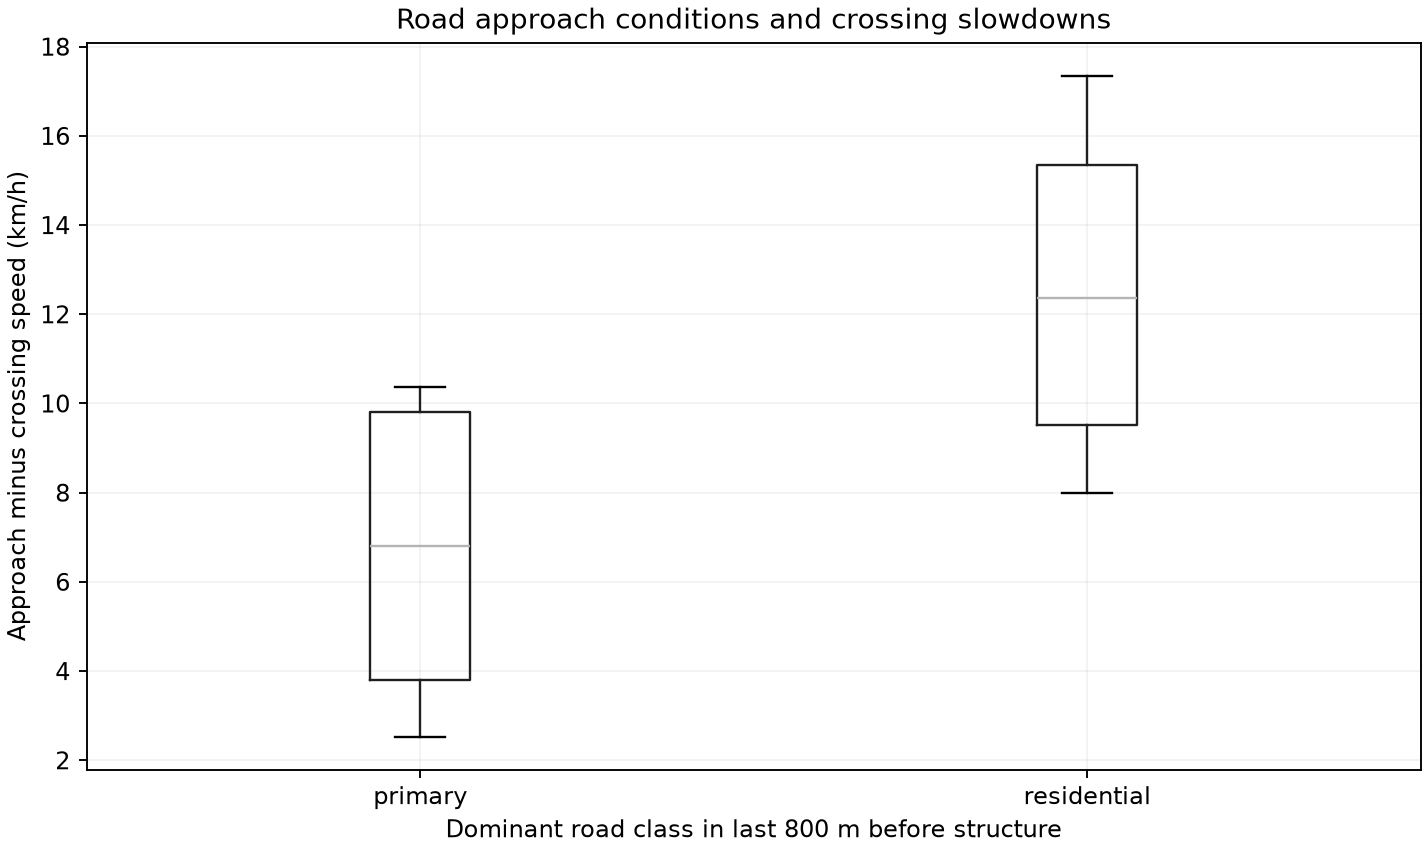

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

legs = pd.read_csv("movement_legs.csv")
visits = pd.read_csv("aoi_visits.csv")
extra = {}
extra["crossings"] = pd.read_csv("crossings.csv")
extra["aois"] = pd.read_csv("aois.csv")


def evidence(case, index, df, user_df, legs, visits, extra):
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)
    moving = user_df[user_df.activity_state.eq("travelling")].copy()
    done = df[df.status.eq("completed")].copy()
    value = {}
    if case == 21:
        order = ["primary", "secondary", "tertiary", "residential"]
        moving = moving.merge(
            legs[["leg_id", "period"]], on="leg_id", validate="many_to_one"
        )
        if index == 1:
            summary = (
                moving.groupby("fclass")[["step_distance_km", "step_duration_s"]]
                .sum()
                .reindex(order)
            )
            summary["movement_speed_kmh"] = (
                summary.step_distance_km / summary.step_duration_s * 3600
            )
            summary["completions"] = done.delivery_fclass.value_counts().reindex(
                order, fill_value=0
            )
            summary["completions_per_km"] = (
                summary.completions / summary.step_distance_km
            )
            ax.bar(
                order,
                summary.movement_speed_kmh,
                color="#5c8ea7",
                alpha=0.8,
                label="Movement speed",
            )
            twin = ax.twinx()
            twin.plot(order, summary.completions_per_km, "o-", color="#bd7843")
            ax.set(ylabel="Distance / moving time (km/h)", xlabel="Native OSM fclass")
            twin.set_ylabel("Delivery completions per travelled km", color="#bd7843")
            value = {"road_class_summary": summary.to_dict("index")}
        elif index == 2:
            summary = (
                moving.groupby(["period", "fclass"])
                .step_distance_km.sum()
                .unstack(fill_value=0)
            )
            summary = summary.div(summary.sum(axis=1), axis=0).reindex(
                ["early", "late"]
            )
            summary[order].plot.bar(stacked=True, ax=ax, rot=0)
            ax.set(
                ylabel="Share of all moving distance",
                xlabel="First / second half of scheduled delivery stops",
            )
            tasks = done.merge(
                legs[["leg_id", "period"]], left_on="arrival_leg_id", right_on="leg_id"
            )
            value = {
                "distance_shares": summary.to_dict("index"),
                "completion_counts": tasks.period.value_counts().to_dict(),
            }
        else:
            # Smooth spatial AND temporal event kernel, independently measured
            # from task-completion positions/times rather than a generator label.
            frames = []
            for tid, q in moving.groupby("trajectory_id"):
                t = done[done.trajectory_id.eq(tid)]
                x = q[["lng", "lat"]].to_numpy() * [95.2, 111]
                y = t[["delivery_lng", "delivery_lat"]].to_numpy() * [95.2, 111]
                ds = np.linalg.norm(x[:, None] - y[None, :], axis=2)
                a = (
                    pd.to_datetime(q.gps_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                b = (
                    pd.to_datetime(t.completion_time, format="mixed")
                    .astype("int64")
                    .to_numpy()
                )
                dt = abs(a[:, None] - b[None, :]) / 6e10
                q = q.copy()
                q["nearby_activity"] = (np.exp(-ds / 0.30) * np.exp(-dt / 30)).sum(
                    axis=1
                )
                frames.append(q)
            points = pd.concat(frames)
            values = {}
            for cls in order:
                q = points[points.fclass.eq(cls)]
                bins = pd.qcut(q.nearby_activity, 5, duplicates="drop")
                med = q.groupby(bins, observed=True)[
                    ["nearby_activity", "speed_kmh"]
                ].median()
                line = ax.plot(med.nearby_activity, med.speed_kmh, "o-", label=cls)[0]
                sample = q.sample(min(350, len(q)), random_state=17)
                ax.scatter(
                    sample.nearby_activity,
                    sample.speed_kmh,
                    s=6,
                    alpha=0.10,
                    color=line.get_color(),
                )
                values[cls] = {
                    "points": len(q),
                    "spearman": q.nearby_activity.corr(q.speed_kmh, method="spearman"),
                    "low_to_high_activity_speed_drop_kmh": (
                        med.speed_kmh.iloc[0] - med.speed_kmh.iloc[-1]
                    ),
                    "quintile_medians": med.to_dict("list"),
                }
            ax.set(
                xlabel=(
                    "Nearby completion intensity (300 m / 30 min exponential kernel)"
                ),
                ylabel="Median moving speed (km/h)",
            )
            ax.legend()
            value = {"within_class_evidence": values}
    elif case == 22:
        if index == 1:
            counts = (
                done.groupby(["service_date", "aoi_id"]).size().unstack(fill_value=0)
            )
            span = user_df.groupby("trajectory_id").gps_time.agg(["min", "max"])
            duration = (
                pd.to_datetime(span["max"], format="mixed")
                - pd.to_datetime(span["min"], format="mixed")
            ).dt.total_seconds()
            shares = (
                visits.groupby(["trajectory_id", "aoi_id"])
                .duration_s.sum()
                .unstack(fill_value=0)
                .div(duration, axis=0)
            )
            summary = pd.DataFrame(
                {
                    "mean_deliveries_per_day": counts.mean(),
                    "mean_work_time_share": shares.mean(),
                }
            )
            summary.plot.bar(
                y="mean_deliveries_per_day", ax=ax, rot=0, legend=False, color="#608ea4"
            )
            ax.set(
                ylabel="Completed deliveries per observed day", xlabel="Constructed AOI"
            )
            twin = ax.twinx()
            twin.plot(
                np.arange(len(summary)),
                summary.mean_work_time_share * 100,
                "o-",
                color="#bd7843",
            )
            twin.set_ylabel("Mean observed workday time (%)")
            value = {
                "aoi_summary": summary.to_dict("index"),
                "observed_days": counts.shape[0],
                "regular_destination_fclasses": sorted(
                    done[done.regular_aoi.eq("yes")].delivery_fclass.unique().tolist()
                ),
                "fixed_receipt_sites": (
                    extra["receipt_events"]
                    .groupby("aoi_id")[["lng", "lat"]]
                    .nunique()
                    .to_dict("index")
                ),
            }
        elif index == 2:
            q = legs[legs.purpose.eq("delivery")]
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
            ax = axes[0]
            ax.boxplot(
                [q[q.period.eq(p)].route_directness_ratio for p in ["early", "late"]],
                tick_labels=["Early", "Late"],
            )
            ax.set(
                xlabel="Delivery route phase",
                ylabel="Travelled / straight-line distance",
                title=(
                    "Later delivery routes are more direct\nLower ratio = less detour"
                ),
            )
            dates = sorted(q.service_date.unique())
            totals = moving.groupby("service_date")[
                ["step_distance_km", "step_duration_s"]
            ].sum()
            baseline = totals.step_distance_km / totals.step_duration_s * 3600
            late = q[q.period.eq("late")].copy()
            late["day_mean_movement_speed_kmh"] = late.service_date.map(baseline)
            late["difference_from_day_mean_kmh"] = (
                late.mean_speed_kmh - late.day_mean_movement_speed_kmh
            )
            above = late.difference_from_day_mean_kmh.gt(0)
            x = late.service_date.map({day: i for i, day in enumerate(dates)}).to_numpy(
                dtype=float
            )
            x += np.where(late.groupby("service_date").cumcount().eq(0), -0.12, 0.12)
            axes[1].axhline(
                0,
                color="#555555",
                linewidth=1,
                linestyle="--",
                label="Same as day mean",
            )
            for mask, color, label in [
                (above, "#3976a8", "Above day mean"),
                (~above, "#c77c3d", "At or below day mean"),
            ]:
                axes[1].scatter(
                    x[mask],
                    late.loc[mask, "difference_from_day_mean_kmh"],
                    color=color,
                    s=48,
                    label=f"{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})",
                )
            axes[1].set(
                xticks=np.arange(len(dates)),
                xticklabels=[day[5:] for day in dates],
                xlabel="Workday — each point is a delivery leg as time drew to a close",
                ylabel="Leg speed − day mean movement speed (km/h)",
                title=(
                    "As time drew to a close:\nMore direct does not guarantee"
                    " above-average speed"
                ),
            )
            axes[1].margins(y=0.30)
            axes[1].tick_params(axis="x", rotation=45, labelsize=8)
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(axis="y", alpha=0.15)
            value = {
                "period_means": (
                    q.groupby("period")[["route_directness_ratio", "mean_speed_kmh"]]
                    .mean()
                    .to_dict("index")
                ),
                "day_mean_definition": (
                    "All moving GPS distance / all moving GPS time, including return"
                    " legs and excluding stops"
                ),
                "daily_mean_movement_speed_kmh": baseline.to_dict(),
                "late_delivery_legs": len(late),
                "late_legs_above_day_mean": int(above.sum()),
                "late_share_above_day_mean": float(above.mean()),
                "late_leg_comparison": (
                    late[
                        [
                            "leg_id",
                            "service_date",
                            "mean_speed_kmh",
                            "day_mean_movement_speed_kmh",
                            "difference_from_day_mean_kmh",
                        ]
                    ].to_dict("records")
                ),
            }
        elif index == 3:
            q = done.copy()
            stamp = pd.to_datetime(q.completion_time, format="mixed")
            q["completion_hour"] = (
                stamp.dt.hour + stamp.dt.minute / 60 + stamp.dt.second / 3600
            )
            q["window_hours"] = (
                pd.to_datetime(q.time_window_end) - pd.to_datetime(q.time_window_start)
            ).dt.total_seconds() / 3600
            plt.close(fig)
            fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), constrained_layout=True)
            ax = axes[0]
            groups = [
                q[q.regular_aoi.eq("no") & q.window_hours.lt(9)],
                q[q.regular_aoi.eq("no") & q.window_hours.ge(9)],
                q[q.regular_aoi.eq("yes") & q.window_hours.ge(9)],
            ]
            labels = [
                "Non-regular AOIs\nWindow <9 h",
                "Non-regular AOIs\nWindow ≥9 h",
                "Regular AOIs (A/B)\nWindow ≥9 h",
            ]
            colors = ["#4f846c", "#3976a8", "#c77c3d"]
            boxes = ax.boxplot(
                [g.completion_hour for g in groups],
                tick_labels=labels,
                patch_artist=True,
            )
            for box, color in zip(boxes["boxes"], colors):
                box.set_facecolor(color)
                box.set_alpha(0.45)
            for i, g in enumerate(groups, 1):
                median = g.completion_hour.median()
                h = int(median)
                minute = int(round((median - h) * 60))
                ax.text(
                    i,
                    17.8,
                    f"n={len(g)}\nMedian {h:02}:{minute:02}",
                    ha="center",
                    fontsize=9,
                )
            ax.set(
                ylabel="Task completion time (Shanghai)",
                title="Both non-regular window groups finish earlier",
                ylim=(7.5, 18.5),
            )
            ax.yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            ax.tick_params(axis="x", labelsize=8)
            for g, label, color, marker in zip(groups, labels, colors, ["o", "s", "^"]):
                axes[1].scatter(
                    g.window_hours,
                    g.completion_hour,
                    s=16,
                    alpha=0.45,
                    color=color,
                    marker=marker,
                    label=label.replace("\n", "; "),
                )
            axes[1].set(
                xlabel="Service-window duration (hours)",
                ylabel="Task completion time (Shanghai)",
                title="Wide windows alone do not explain later completion",
                ylim=(7.5, 19.5),
            )
            axes[1].yaxis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
            axes[1].legend(loc="upper left", fontsize=8, frameon=False)
            axes[1].grid(alpha=0.15)
            nvisits = visits.groupby(["service_date", "aoi_id"]).size()
            value = {
                "group_medians": (
                    q.groupby("regular_aoi")[["completion_hour", "window_hours"]]
                    .median()
                    .to_dict("index")
                ),
                "regular_aoi_visits_per_day": (
                    nvisits.unstack(fill_value=0)[["A", "B"]].to_dict("list")
                ),
                "irregular_by_window_median_hour": (
                    q[q.regular_aoi.eq("no")]
                    .assign(
                        window_group=lambda d: np.where(
                            d.window_hours < 9, "Narrower (<9h)", "Wide (9h+)"
                        )
                    )
                    .groupby("window_group")
                    .completion_hour.median()
                    .to_dict()
                ),
                "plotted_groups": {
                    label.replace("\n", "; "): {
                        "tasks": len(g),
                        "median_completion_hour": float(g.completion_hour.median()),
                        "window_hours_min": float(g.window_hours.min()),
                        "window_hours_max": float(g.window_hours.max()),
                    }
                    for label, g in zip(labels, groups)
                },
                "uncompleted_tasks_excluded": int(df.status.ne("completed").sum()),
            }
        else:
            irregular = df[df.regular_aoi.eq("no")]
            summary = (
                irregular.groupby(["service_date", "status"])
                .size()
                .unstack(fill_value=0)
            )
            summary.plot.bar(stacked=True, ax=ax, rot=50)
            ax.set(ylabel="Available irregular-AOI tasks", xlabel="Workday")
            pending = irregular[irregular.status.eq("pending")]
            dates = pending.service_date.unique().tolist()
            min_dist = {}
            for day in dates:
                gps = user_df[user_df.service_date.eq(day)]
                destinations = pending[pending.service_date.eq(day)][
                    ["aoi_id", "delivery_lng", "delivery_lat"]
                ].drop_duplicates()
                for r in destinations.itertuples():
                    ds = np.linalg.norm(
                        (
                            gps[["lng", "lat"]].to_numpy()
                            - [r.delivery_lng, r.delivery_lat]
                        )
                        * [95200, 111000],
                        axis=1,
                    )
                    min_dist[r.aoi_id] = float(ds.min())
            value = {
                "pending_dates": dates,
                "pending_tasks": len(pending),
                "minimum_GPS_distance_to_unvisited_AOI_m": min_dist,
                "anomaly_day_irregular_visit_count": int(
                    len(
                        visits[
                            visits.service_date.isin(dates)
                            & ~visits.aoi_id.isin(["A", "B"])
                        ]
                    )
                ),
            }
    elif case == 23:
        q = legs[legs.purpose.eq("delivery")].copy()
        # Initial departure is not between two completed task locations.
        q = q[q.groupby("trajectory_id").cumcount().gt(0)]
        if index == 1:
            q = q[q.period.ne("exception") & q.separation_km.between(0.7, 1.4)]
            q["oneway_group"] = np.where(
                q.oneway_share >= 0.55,
                "High (55%+)",
                np.where(q.oneway_share <= 0.25, "Low (0–25%)", "Middle"),
            )
            q = q[q.oneway_group.ne("Middle")]
            for name, s in q.groupby("oneway_group"):
                ax.scatter(
                    s.separation_km, s.route_directness_ratio, label=name, alpha=0.6
                )
            ax.set(
                xlabel="Task endpoint separation (km)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "matched_separation_range_km": [0.7, 1.4],
                "group_means": (
                    q.groupby("oneway_group")[
                        ["separation_km", "route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "within_period_group_means": (
                    q.groupby(["period", "oneway_group"])[
                        ["route_directness_ratio", "mean_speed_kmh"]
                    ]
                    .mean()
                    .reset_index()
                    .to_dict("records")
                ),
            }
        elif index == 2:
            means = (
                q[q.period.ne("exception")]
                .groupby("period")[["mean_speed_kmh", "route_directness_ratio"]]
                .mean()
                .reindex(["early", "midday", "late"])
            )
            stamp = pd.to_datetime(q.departure_time, format="mixed")
            q["departure_hour"] = (
                stamp - stamp.dt.normalize()
            ).dt.total_seconds() / 3600
            centers = np.arange(
                np.floor(q.departure_hour.min() * 6) / 6,
                np.ceil(q.departure_hour.max() * 6) / 6 + 1 / 12,
                1 / 6,
            )
            windows = []
            for center in centers:
                subset = q[q.departure_hour.between(center - 0.5, center + 0.5)]
                windows.append(
                    {
                        "center_hour": float(center),
                        "legs": len(subset),
                        **{
                            column: (
                                float(subset[column].median())
                                if len(subset) >= 8
                                else None
                            )
                            for column in ["mean_speed_kmh", "route_directness_ratio"]
                        },
                    }
                )
            trend = pd.DataFrame(windows)
            plt.close(fig)
            fig, axes = plt.subplots(
                2, 1, figsize=(9.5, 7), sharex=True, constrained_layout=True
            )
            fig.suptitle("Speed and detour over actual departure time", fontsize=15)
            for axis, column, color, title in [
                (
                    axes[0],
                    "mean_speed_kmh",
                    "#3976a8",
                    "Movement speed of each task-to-task leg",
                ),
                (
                    axes[1],
                    "route_directness_ratio",
                    "#c77c3d",
                    "Route detour of the same legs at the same times",
                ),
            ]:
                normal = q[q.period.ne("exception")]
                exception = q[q.period.eq("exception")]
                axis.scatter(
                    normal.departure_hour,
                    normal[column],
                    s=22,
                    color=color,
                    alpha=0.45,
                    label=f"Task-to-task legs ({len(normal)}; 14 days)",
                )
                axis.scatter(
                    exception.departure_hour,
                    exception[column],
                    s=110,
                    color="#8c405f",
                    marker="*",
                    label="Exceptional leg (insight 4)",
                    zorder=4,
                )
                axis.plot(
                    trend.center_hour,
                    trend[column],
                    color=color,
                    linewidth=2.5,
                    label="60-min rolling median (≥8 legs)",
                )
                axis.set_title(title, fontsize=11)
                axis.grid(axis="y", alpha=0.15)
                axis.margins(x=0.03, y=0.30)
                axis.legend(loc="upper left", fontsize=8, frameon=False)
            axes[0].set_ylabel("Mean movement speed (km/h)")
            axes[1].set_ylabel(
                "Travelled / straight-line distance\nHigher = more detour"
            )
            ticks = np.arange(
                np.floor(q.departure_hour.min()), np.ceil(q.departure_hour.max()) + 1
            )
            axes[1].set(
                xticks=ticks,
                xticklabels=[f"{int(h):02}:00" for h in ticks],
                xlabel="Actual leg departure time (Shanghai local time; days overlaid)",
            )
            value = {
                "period_means": means.to_dict("index"),
                "period_means_note": (
                    "Legacy phase aggregates retained for compatibility; not used to"
                    " draw this chart."
                ),
                "plotted_task_to_task_legs": len(q),
                "exception_legs_included": int(q.period.eq("exception").sum()),
                "rolling_window_minutes": 60,
                "minimum_legs_per_window": 8,
                "clock_time_rolling_medians": [
                    window for window in windows if window["legs"] >= 8
                ],
                "omitted_window_centers_hour": [
                    window["center_hour"] for window in windows if window["legs"] < 8
                ],
            }
        elif index == 3:
            p = (
                q[q.period.ne("exception")]
                .groupby(["service_date", "period"])
                .agg(
                    detour_sd=("route_directness_ratio", "std"),
                    speed_sd=("mean_speed_kmh", "std"),
                    transitions=("fclass_transitions", "sum"),
                    distance=("distance_km", "sum"),
                )
            )
            p["transitions_per_km"] = p.transitions / p.distance
            ax.scatter(
                p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap="viridis", s=50
            )
            fig.colorbar(ax.collections[0], ax=ax, label="Across-leg speed SD (km/h)")
            ax.set(
                xlabel="Native fclass transitions per travelled km",
                ylabel="Within-period route-ratio SD",
            )
            cut = p.transitions_per_km.median()
            p["transition_group"] = np.where(
                p.transitions_per_km > cut, "Frequent", "Less frequent"
            )
            value = {
                "correlation_transition_frequency_detour_sd": p.transitions_per_km.corr(
                    p.detour_sd
                ),
                "group_means": (
                    p.groupby("transition_group")[
                        ["detour_sd", "speed_sd", "transitions_per_km"]
                    ]
                    .mean()
                    .to_dict("index")
                ),
                "period_count": len(p),
            }
        else:
            normal = q[q.period.ne("exception")]
            exception = q[q.period.eq("exception")]
            ax.scatter(
                normal.oneway_share * 100,
                normal.route_directness_ratio,
                alpha=0.4,
                label="Other task legs",
            )
            ax.scatter(
                exception.oneway_share * 100,
                exception.route_directness_ratio,
                marker="*",
                s=220,
                color="#c66643",
                label="Exceptional period",
            )
            ax.set(
                xlabel="One-way-road distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {
                "exception": (
                    exception[
                        [
                            "leg_id",
                            "route_directness_ratio",
                            "oneway_share",
                            "mean_speed_kmh",
                            "distance_km",
                            "separation_km",
                        ]
                    ].to_dict("records")
                ),
                "normal_speed_10_90_percentiles": (
                    normal.mean_speed_kmh.quantile([0.1, 0.9]).tolist()
                ),
                "schema_oneway_unit_assumption": (
                    "2.01 interpreted provisionally as percent, pending user"
                    " confirmation"
                ),
            }
    elif case == 24:
        if index == 1:
            q = legs[legs.purpose.str.startswith("road_condition")]
            q.boxplot(column="speed_std_kmh", by="purpose", ax=ax)
            fig.suptitle("")
            ax.set(
                xlabel="Road condition",
                ylabel="Short-term GPS speed SD (km/h)",
                title="Stable residential travel versus alternating road classes",
            )
            value = {
                "condition_means": (
                    q.groupby("purpose")[
                        [
                            "speed_std_kmh",
                            "residential_share",
                            "tertiary_share",
                            "fclass_transitions",
                        ]
                    ]
                    .mean()
                    .to_dict("index")
                )
            }
        else:
            q = extra["crossings"].merge(
                legs,
                left_on="crossing_leg_id",
                right_on="leg_id",
                validate="one_to_one",
            )
            low = moving[moving.speed_kmh < 12].groupby("leg_id").step_duration_s.sum()
            q["low_speed_seconds"] = q.leg_id.map(low).fillna(0)
            approach = legs.set_index("leg_id").mean_speed_kmh
            q["speed_drop_kmh"] = q.approach_leg_id.map(approach) - q.mean_speed_kmh
            if index == 2:
                # Fluctuation is within-crossing GPS speed SD, not variation
                # between the average speeds of different crossings.
                recomputed = moving.groupby("leg_id").speed_kmh.agg(
                    lambda s: float(np.std(s.to_numpy(), ddof=0))
                )
                np.testing.assert_allclose(
                    q.speed_std_kmh, q.leg_id.map(recomputed), atol=1e-8
                )
                plt.close(fig)
                fig, axes = plt.subplots(
                    1, 2, figsize=(12.5, 5.5), constrained_layout=True
                )
                ax = axes[0]
                structures = (
                    q[["structure_osm_way_id", "structure_type"]]
                    .drop_duplicates()
                    .sort_values("structure_type")
                )
                ticks = []
                labels = []
                for axis, column, title, ylabel in [
                    (
                        axes[0],
                        "low_speed_seconds",
                        "Longer low-speed time later in the workday",
                        "Time below 12 km/h per crossing (seconds)",
                    ),
                    (
                        axes[1],
                        "speed_std_kmh",
                        "Greater speed fluctuations later in the workday",
                        "Within-crossing GPS speed SD (km/h)",
                    ),
                ]:
                    for i, structure in enumerate(structures.itertuples()):
                        group = q[
                            q.structure_osm_way_id.eq(structure.structure_osm_way_id)
                        ]
                        paired = group.pivot(
                            index=["service_date", "approach_fclass"],
                            columns="period",
                            values=column,
                        )
                        assert paired[["early", "late"]].notna().all().all()
                        for row in paired.itertuples():
                            axis.plot(
                                [i * 3, i * 3 + 1],
                                [row.early, row.late],
                                color="#aab4bc",
                                alpha=0.5,
                                linewidth=0.8,
                            )
                        for j, (period, color) in enumerate(
                            [("early", "#3976a8"), ("late", "#c77c3d")]
                        ):
                            values = group.loc[group.period.eq(period), column]
                            axis.scatter(
                                np.full(len(values), i * 3 + j),
                                values,
                                s=24,
                                color=color,
                                alpha=0.7,
                                label=(
                                    period.capitalize() + " crossing"
                                    if i == 0
                                    else None
                                ),
                                zorder=3,
                            )
                            mean = values.mean()
                            axis.plot(
                                [i * 3 + j - 0.18, i * 3 + j + 0.18],
                                [mean, mean],
                                color="black",
                                linewidth=2,
                                label="Group mean" if i == 0 and j == 0 else None,
                                zorder=4,
                            )
                            axis.annotate(
                                f"{mean:.2f}",
                                (i * 3 + j, values.max()),
                                xytext=(0, 10),
                                textcoords="offset points",
                                ha="center",
                                fontweight="bold",
                                fontsize=10,
                            )
                        if axis is axes[0]:
                            ticks.extend([i * 3, i * 3 + 1])
                            labels.extend(
                                [
                                    f"Early\n{structure.structure_type.title()}",
                                    f"Late\n{structure.structure_type.title()}",
                                ]
                            )
                    axis.set(
                        xticks=ticks,
                        xticklabels=labels,
                        ylabel=ylabel,
                        title=title,
                        xlabel=(
                            "Paired within the same day, structure and approach class"
                        ),
                    )
                    axis.set_ylim(
                        0,
                        (
                            group[column].max() * 1.5
                            if column == "speed_std_kmh"
                            else q[column].max() * 1.5
                        ),
                    )
                    axis.legend(loc="upper left", fontsize=8, frameon=False)
                    axis.grid(axis="y", alpha=0.15)
                value = {
                    "structure_period_means": (
                        q.groupby(["structure_osm_way_id", "structure_type", "period"])[
                            ["low_speed_seconds", "speed_std_kmh", "mean_speed_kmh"]
                        ]
                        .mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                    "crossings": len(q),
                    "unique_structures": q.structure_osm_way_id.nunique(),
                }
            else:
                q.boxplot(column="speed_drop_kmh", by="approach_fclass", ax=ax)
                fig.suptitle("")
                ax.set(
                    xlabel="Dominant road class in last 800 m before structure",
                    ylabel="Approach minus crossing speed (km/h)",
                    title="Road approach conditions and crossing slowdowns",
                )
                value = {
                    "approach_means": (
                        q.groupby("approach_fclass")[
                            ["speed_drop_kmh", "approach_dominant_share"]
                        ]
                        .mean()
                        .to_dict("index")
                    ),
                    "within_structure_period_means": (
                        q.groupby(["structure_osm_way_id", "period", "approach_fclass"])
                        .speed_drop_kmh.mean()
                        .reset_index()
                        .to_dict("records")
                    ),
                }
    elif case == 25:
        if index == 1:
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=0.5
                )
            ax.set(
                xlabel="Travelled / straight-line distance",
                ylabel="Leg movement speed (km/h)",
            )
            ax.legend()
            summary = legs.groupby("region_id")[
                ["route_directness_ratio", "mean_speed_kmh"]
            ].mean()
            summary["delivery_volume"] = done.groupby("region_id").size()
            value = {
                "region_means": summary.to_dict("index"),
                "region_role_mapping": (
                    extra["regions"][["region_id", "comparison_role"]].to_dict(
                        "records"
                    )
                ),
            }
        elif index == 2:
            summary = legs.groupby(["region_id", "period"])[
                ["route_directness_ratio", "primary_share", "residential_share"]
            ].mean()
            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)
            ax.set(
                ylabel="Mean travelled / straight-line distance",
                xlabel="Constructed service region",
            )
            value = {"region_period_means": summary.reset_index().to_dict("records")}
        else:
            values = {}
            for name, q in legs.groupby("region_id"):
                ax.scatter(
                    q.oneway_share * 100,
                    q.route_directness_ratio,
                    label=name,
                    alpha=0.5,
                )
                values[name] = {
                    "pearson": q.oneway_share.corr(q.route_directness_ratio),
                    "spearman": q.oneway_share.corr(
                        q.route_directness_ratio, method="spearman"
                    ),
                    "legs": len(q),
                    "oneway_share_unique_values": q.oneway_share.nunique(),
                    "route_ratio_unique_values": q.route_directness_ratio.nunique(),
                }
            ax.set(
                xlabel="One-way-road share of travelled distance (%)",
                ylabel="Travelled / straight-line distance",
            )
            ax.legend()
            value = {"within_region_associations": values}
    ax.grid(alpha=0.15)
    return json.loads(json.dumps(value, default=lambda x: x.item()))


evidence_value = evidence(24, 3, df, user_df, legs, visits, extra)
print(evidence_value)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "road_backed_evidence_3",
  "insight_type": "factor_relationship",
  "insight": "Bridge and tunnel crossings approached from residential roads tend to show larger speed drops than those approached from primary roads.",
  "insight_value": {
    "approach_means": {
      "primary": {
        "speed_drop_kmh": 6.784251681302468,
        "approach_dominant_share": 0.9090081312835449
      },
      "residential": {
        "speed_drop_kmh": 12.52314780840708,
        "approach_dominant_share": 0.6767508435039415
      }
    },
    "within_structure_period_means": [
      {
        "structure_osm_way_id": 50832813,
        "period": "early",
        "approach_fclass": "primary",
        "speed_drop_kmh": 3.953928297811392
      },
      {
        "structure_osm_way_id": 50832813,
        "period": "early",
        "approach_fclass": "residential",
        "speed_drop_kmh": 9.43754239993664
      },
      {
        "structure_osm_way_id": 50832813,
        "period": "late",
        "approach_fclass": "primary",
        "speed_drop_kmh": 9.864194571929945
      },
      {
        "structure_osm_way_id": 50832813,
        "period": "late",
        "approach_fclass": "residential",
        "speed_drop_kmh": 15.702287382354175
      },
      {
        "structure_osm_way_id": 175468780,
        "period": "early",
        "approach_fclass": "primary",
        "speed_drop_kmh": 3.912133935193818
      },
      {
        "structure_osm_way_id": 175468780,
        "period": "early",
        "approach_fclass": "residential",
        "speed_drop_kmh": 9.5800671154918
      },
      {
        "structure_osm_way_id": 175468780,
        "period": "late",
        "approach_fclass": "primary",
        "speed_drop_kmh": 9.406749920274716
      },
      {
        "structure_osm_way_id": 175468780,
        "period": "late",
        "approach_fclass": "residential",
        "speed_drop_kmh": 15.372694335845697
      }
    ]
  },
  "question": "What CSV-derived evidence supports insight 3?",
  "actionable_insight": "Interpret the constructed descriptive association, not an estimated causal effect.",
  "plot": {
    "plot_type": "single_evidence_panel",
    "title": "LaDe 24 insight 3",
    "file": "visualizations/insight_3.png",
    "description": "Calculated from emitted task, GPS and support CSVs."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nlegs = pd.read_csv(\"movement_legs.csv\")\nvisits = pd.read_csv(\"aoi_visits.csv\")\nextra = {}\nextra[\"crossings\"] = pd.read_csv(\"crossings.csv\")\nextra[\"aois\"] = pd.read_csv(\"aois.csv\")\n\ndef evidence(case, index, df, user_df, legs, visits, extra):\n    import json\n    import numpy as np\n    import pandas as pd\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.4, 5.0), constrained_layout=True)\n    moving = user_df[user_df.activity_state.eq('travelling')].copy()\n    done = df[df.status.eq('completed')].copy()\n    value = {}\n    if case == 21:\n        order = ['primary', 'secondary', 'tertiary', 'residential']\n        moving = moving.merge(legs[['leg_id', 'period']], on='leg_id', validate='many_to_one')\n        if index == 1:\n            summary = moving.groupby('fclass')[['step_distance_km', 'step_duration_s']].sum().reindex(order)\n            summary['movement_speed_kmh'] = summary.step_distance_km/summary.step_duration_s*3600\n            summary['completions'] = done.delivery_fclass.value_counts().reindex(order, fill_value=0)\n            summary['completions_per_km'] = summary.completions/summary.step_distance_km\n            ax.bar(order, summary.movement_speed_kmh, color='#5c8ea7', alpha=.8, label='Movement speed')\n            twin = ax.twinx(); twin.plot(order, summary.completions_per_km, 'o-', color='#bd7843')\n            ax.set(ylabel='Distance / moving time (km/h)', xlabel='Native OSM fclass')\n            twin.set_ylabel('Delivery completions per travelled km', color='#bd7843')\n            value = {'road_class_summary': summary.to_dict('index')}\n        elif index == 2:\n            summary = moving.groupby(['period', 'fclass']).step_distance_km.sum().unstack(fill_value=0)\n            summary = summary.div(summary.sum(axis=1), axis=0).reindex(['early', 'late'])\n            summary[order].plot.bar(stacked=True, ax=ax, rot=0)\n            ax.set(ylabel='Share of all moving distance', xlabel='First / second half of scheduled delivery stops')\n            tasks = done.merge(legs[['leg_id', 'period']], left_on='arrival_leg_id', right_on='leg_id')\n            value = {'distance_shares': summary.to_dict('index'), 'completion_counts': tasks.period.value_counts().to_dict()}\n        else:\n            # Smooth spatial AND temporal event kernel, independently measured\n            # from task-completion positions/times rather than a generator label.\n            frames = []\n            for tid, q in moving.groupby('trajectory_id'):\n                t = done[done.trajectory_id.eq(tid)]\n                x = q[['lng', 'lat']].to_numpy()*[95.2, 111]\n                y = t[['delivery_lng', 'delivery_lat']].to_numpy()*[95.2, 111]\n                ds = np.linalg.norm(x[:, None]-y[None, :], axis=2)\n                a = pd.to_datetime(q.gps_time, format='mixed').astype('int64').to_numpy()\n                b = pd.to_datetime(t.completion_time, format='mixed').astype('int64').to_numpy()\n                dt = abs(a[:, None]-b[None, :])/6e10\n                q = q.copy(); q['nearby_activity'] = (np.exp(-ds/.30)*np.exp(-dt/30)).sum(axis=1)\n                frames.append(q)\n            points = pd.concat(frames); values = {}\n            for cls in order:\n                q = points[points.fclass.eq(cls)]\n                bins = pd.qcut(q.nearby_activity, 5, duplicates='drop')\n                med = q.groupby(bins, observed=True)[['nearby_activity', 'speed_kmh']].median()\n                line = ax.plot(med.nearby_activity, med.speed_kmh, 'o-', label=cls)[0]\n                sample = q.sample(min(350, len(q)), random_state=17)\n                ax.scatter(sample.nearby_activity, sample.speed_kmh, s=6, alpha=.10, color=line.get_color())\n                values[cls] = {'points': len(q), 'spearman': q.nearby_activity.corr(q.speed_kmh, method='spearman'),\n                    'low_to_high_activity_speed_drop_kmh': med.speed_kmh.iloc[0]-med.speed_kmh.iloc[-1],\n                    'quintile_medians': med.to_dict('list')}\n            ax.set(xlabel='Nearby completion intensity (300 m / 30 min exponential kernel)', ylabel='Median moving speed (km/h)'); ax.legend()\n            value = {'within_class_evidence': values}\n    elif case == 22:\n        if index == 1:\n            counts = done.groupby(['service_date', 'aoi_id']).size().unstack(fill_value=0)\n            span = user_df.groupby('trajectory_id').gps_time.agg(['min', 'max'])\n            duration = (pd.to_datetime(span['max'], format='mixed')-pd.to_datetime(span['min'], format='mixed')).dt.total_seconds()\n            shares = visits.groupby(['trajectory_id', 'aoi_id']).duration_s.sum().unstack(fill_value=0).div(duration, axis=0)\n            summary = pd.DataFrame({'mean_deliveries_per_day': counts.mean(), 'mean_work_time_share': shares.mean()})\n            summary.plot.bar(y='mean_deliveries_per_day', ax=ax, rot=0, legend=False, color='#608ea4')\n            ax.set(ylabel='Completed deliveries per observed day', xlabel='Constructed AOI')\n            twin = ax.twinx(); twin.plot(np.arange(len(summary)), summary.mean_work_time_share*100, 'o-', color='#bd7843'); twin.set_ylabel('Mean observed workday time (%)')\n            value = {'aoi_summary': summary.to_dict('index'), 'observed_days': counts.shape[0],\n                'regular_destination_fclasses': sorted(done[done.regular_aoi.eq('yes')].delivery_fclass.unique().tolist()),\n                'fixed_receipt_sites': extra['receipt_events'].groupby('aoi_id')[['lng', 'lat']].nunique().to_dict('index')}\n        elif index == 2:\n            q = legs[legs.purpose.eq('delivery')]\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13,5.4),constrained_layout=True);ax=axes[0]\n            ax.boxplot([q[q.period.eq(p)].route_directness_ratio for p in ['early','late']],\n                tick_labels=['Early','Late'])\n            ax.set(xlabel='Delivery route phase',ylabel='Travelled / straight-line distance',\n                title='Later delivery routes are more direct\\nLower ratio = less detour')\n            dates=sorted(q.service_date.unique())\n            totals=moving.groupby('service_date')[['step_distance_km','step_duration_s']].sum()\n            baseline=totals.step_distance_km/totals.step_duration_s*3600\n            late=q[q.period.eq('late')].copy()\n            late['day_mean_movement_speed_kmh']=late.service_date.map(baseline)\n            late['difference_from_day_mean_kmh']=late.mean_speed_kmh-late.day_mean_movement_speed_kmh\n            above=late.difference_from_day_mean_kmh.gt(0)\n            x=late.service_date.map({day:i for i,day in enumerate(dates)}).to_numpy(dtype=float)\n            x+=np.where(late.groupby('service_date').cumcount().eq(0),-.12,.12)\n            axes[1].axhline(0,color='#555555',linewidth=1,linestyle='--',label='Same as day mean')\n            for mask,color,label in [(above,'#3976a8','Above day mean'),(~above,'#c77c3d','At or below day mean')]:\n                axes[1].scatter(x[mask],late.loc[mask,'difference_from_day_mean_kmh'],color=color,s=48,\n                    label=f'{label}: {int(mask.sum())}/{len(late)} ({mask.mean():.1%})')\n            axes[1].set(xticks=np.arange(len(dates)),xticklabels=[day[5:] for day in dates],\n                xlabel='Workday — each point is a delivery leg as time drew to a close',ylabel='Leg speed − day mean movement speed (km/h)',\n                title='As time drew to a close:\\nMore direct does not guarantee above-average speed')\n            axes[1].margins(y=.30)\n            axes[1].tick_params(axis='x',rotation=45,labelsize=8)\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(axis='y',alpha=.15)\n            value = {'period_means': q.groupby('period')[['route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'day_mean_definition':'All moving GPS distance / all moving GPS time, including return legs and excluding stops',\n                'daily_mean_movement_speed_kmh':baseline.to_dict(),\n                'late_delivery_legs':len(late),'late_legs_above_day_mean':int(above.sum()),\n                'late_share_above_day_mean':float(above.mean()),\n                'late_leg_comparison':late[['leg_id','service_date','mean_speed_kmh','day_mean_movement_speed_kmh','difference_from_day_mean_kmh']].to_dict('records')}\n        elif index == 3:\n            q = done.copy(); stamp = pd.to_datetime(q.completion_time, format='mixed')\n            q['completion_hour'] = stamp.dt.hour+stamp.dt.minute/60+stamp.dt.second/3600\n            q['window_hours'] = (pd.to_datetime(q.time_window_end)-pd.to_datetime(q.time_window_start)).dt.total_seconds()/3600\n            plt.close(fig)\n            fig,axes=plt.subplots(1,2,figsize=(13.5,5.5),constrained_layout=True);ax=axes[0]\n            groups=[q[q.regular_aoi.eq('no')&q.window_hours.lt(9)],\n                    q[q.regular_aoi.eq('no')&q.window_hours.ge(9)],q[q.regular_aoi.eq('yes')&q.window_hours.ge(9)]]\n            labels=['Non-regular AOIs\\nWindow <9 h','Non-regular AOIs\\nWindow ≥9 h','Regular AOIs (A/B)\\nWindow ≥9 h']\n            colors=['#4f846c','#3976a8','#c77c3d']\n            boxes=ax.boxplot([g.completion_hour for g in groups],tick_labels=labels,patch_artist=True)\n            for box,color in zip(boxes['boxes'],colors):box.set_facecolor(color);box.set_alpha(.45)\n            for i,g in enumerate(groups,1):\n                median=g.completion_hour.median();h=int(median);minute=int(round((median-h)*60))\n                ax.text(i,17.8,f'n={len(g)}\\nMedian {h:02}:{minute:02}',ha='center',fontsize=9)\n            ax.set(ylabel='Task completion time (Shanghai)',title='Both non-regular window groups finish earlier',ylim=(7.5,18.5))\n            ax.yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            ax.tick_params(axis='x',labelsize=8)\n            for g,label,color,marker in zip(groups,labels,colors,['o','s','^']):\n                axes[1].scatter(g.window_hours,g.completion_hour,s=16,alpha=.45,\n                    color=color,marker=marker,label=label.replace('\\n','; '))\n            axes[1].set(xlabel='Service-window duration (hours)',ylabel='Task completion time (Shanghai)',\n                title='Wide windows alone do not explain later completion',ylim=(7.5,19.5))\n            axes[1].yaxis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n            axes[1].legend(loc='upper left',fontsize=8,frameon=False)\n            axes[1].grid(alpha=.15)\n            nvisits = visits.groupby(['service_date', 'aoi_id']).size()\n            value = {'group_medians': q.groupby('regular_aoi')[['completion_hour', 'window_hours']].median().to_dict('index'),\n                'regular_aoi_visits_per_day': nvisits.unstack(fill_value=0)[['A', 'B']].to_dict('list'),\n                'irregular_by_window_median_hour': q[q.regular_aoi.eq('no')].assign(window_group=lambda d: np.where(d.window_hours < 9, 'Narrower (<9h)', 'Wide (9h+)')).groupby('window_group').completion_hour.median().to_dict(),\n                'plotted_groups':{label.replace('\\n','; '):{'tasks':len(g),'median_completion_hour':float(g.completion_hour.median()),\n                    'window_hours_min':float(g.window_hours.min()),'window_hours_max':float(g.window_hours.max())}\n                    for label,g in zip(labels,groups)},\n                'uncompleted_tasks_excluded':int(df.status.ne('completed').sum())}\n        else:\n            irregular = df[df.regular_aoi.eq('no')]\n            summary = irregular.groupby(['service_date', 'status']).size().unstack(fill_value=0)\n            summary.plot.bar(stacked=True, ax=ax, rot=50)\n            ax.set(ylabel='Available irregular-AOI tasks', xlabel='Workday')\n            pending = irregular[irregular.status.eq('pending')]; dates = pending.service_date.unique().tolist()\n            min_dist = {}\n            for day in dates:\n                gps = user_df[user_df.service_date.eq(day)]\n                destinations = pending[pending.service_date.eq(day)][['aoi_id', 'delivery_lng', 'delivery_lat']].drop_duplicates()\n                for r in destinations.itertuples():\n                    ds = np.linalg.norm((gps[['lng', 'lat']].to_numpy()-[r.delivery_lng, r.delivery_lat])*[95200, 111000], axis=1)\n                    min_dist[r.aoi_id] = float(ds.min())\n            value = {'pending_dates': dates, 'pending_tasks': len(pending), 'minimum_GPS_distance_to_unvisited_AOI_m': min_dist,\n                'anomaly_day_irregular_visit_count': int(len(visits[visits.service_date.isin(dates)&~visits.aoi_id.isin(['A', 'B'])]))}\n    elif case == 23:\n        q = legs[legs.purpose.eq('delivery')].copy()\n        # Initial departure is not between two completed task locations.\n        q = q[q.groupby('trajectory_id').cumcount().gt(0)]\n        if index == 1:\n            q = q[q.period.ne('exception')&q.separation_km.between(.7, 1.4)]\n            q['oneway_group'] = np.where(q.oneway_share >= .55, 'High (55%+)', np.where(q.oneway_share <= .25, 'Low (0–25%)', 'Middle'))\n            q = q[q.oneway_group.ne('Middle')]\n            for name, s in q.groupby('oneway_group'): ax.scatter(s.separation_km, s.route_directness_ratio, label=name, alpha=.6)\n            ax.set(xlabel='Task endpoint separation (km)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'matched_separation_range_km': [.7, 1.4], 'group_means': q.groupby('oneway_group')[['separation_km', 'route_directness_ratio', 'mean_speed_kmh']].mean().to_dict('index'),\n                'within_period_group_means': q.groupby(['period', 'oneway_group'])[['route_directness_ratio', 'mean_speed_kmh']].mean().reset_index().to_dict('records')}\n        elif index == 2:\n            means = q[q.period.ne('exception')].groupby('period')[['mean_speed_kmh', 'route_directness_ratio']].mean().reindex(['early', 'midday', 'late'])\n            stamp=pd.to_datetime(q.departure_time,format='mixed')\n            q['departure_hour']=(stamp-stamp.dt.normalize()).dt.total_seconds()/3600\n            centers=np.arange(np.floor(q.departure_hour.min()*6)/6,np.ceil(q.departure_hour.max()*6)/6+1/12,1/6)\n            windows=[]\n            for center in centers:\n                subset=q[q.departure_hour.between(center-.5,center+.5)]\n                windows.append({'center_hour':float(center),'legs':len(subset),\n                    **{column:float(subset[column].median()) if len(subset)>=8 else None\n                       for column in ['mean_speed_kmh','route_directness_ratio']}})\n            trend=pd.DataFrame(windows)\n            plt.close(fig)\n            fig,axes=plt.subplots(2,1,figsize=(9.5,7),sharex=True,constrained_layout=True)\n            fig.suptitle('Speed and detour over actual departure time',fontsize=15)\n            for axis,column,color,title in [\n                (axes[0],'mean_speed_kmh','#3976a8','Movement speed of each task-to-task leg'),\n                (axes[1],'route_directness_ratio','#c77c3d','Route detour of the same legs at the same times')]:\n                normal=q[q.period.ne('exception')];exception=q[q.period.eq('exception')]\n                axis.scatter(normal.departure_hour,normal[column],s=22,color=color,alpha=.45,\n                    label=f'Task-to-task legs ({len(normal)}; 14 days)')\n                axis.scatter(exception.departure_hour,exception[column],s=110,color='#8c405f',marker='*',\n                    label='Exceptional leg (insight 4)',zorder=4)\n                axis.plot(trend.center_hour,trend[column],color=color,linewidth=2.5,\n                    label='60-min rolling median (≥8 legs)')\n                axis.set_title(title,fontsize=11)\n                axis.grid(axis='y',alpha=.15)\n                axis.margins(x=.03,y=.30)\n                axis.legend(loc='upper left',fontsize=8,frameon=False)\n            axes[0].set_ylabel('Mean movement speed (km/h)')\n            axes[1].set_ylabel('Travelled / straight-line distance\\nHigher = more detour')\n            ticks=np.arange(np.floor(q.departure_hour.min()),np.ceil(q.departure_hour.max())+1)\n            axes[1].set(xticks=ticks,xticklabels=[f'{int(h):02}:00' for h in ticks],\n                xlabel='Actual leg departure time (Shanghai local time; days overlaid)')\n            value = {'period_means': means.to_dict('index'),\n                'period_means_note':'Legacy phase aggregates retained for compatibility; not used to draw this chart.',\n                'plotted_task_to_task_legs':len(q),'exception_legs_included':int(q.period.eq('exception').sum()),\n                'rolling_window_minutes':60,'minimum_legs_per_window':8,\n                'clock_time_rolling_medians':[window for window in windows if window['legs']>=8],\n                'omitted_window_centers_hour':[window['center_hour'] for window in windows if window['legs']<8]}\n        elif index == 3:\n            p = q[q.period.ne('exception')].groupby(['service_date', 'period']).agg(detour_sd=('route_directness_ratio', 'std'), speed_sd=('mean_speed_kmh', 'std'), transitions=('fclass_transitions', 'sum'), distance=('distance_km', 'sum'))\n            p['transitions_per_km'] = p.transitions/p.distance\n            ax.scatter(p.transitions_per_km, p.detour_sd, c=p.speed_sd, cmap='viridis', s=50)\n            fig.colorbar(ax.collections[0], ax=ax, label='Across-leg speed SD (km/h)')\n            ax.set(xlabel='Native fclass transitions per travelled km', ylabel='Within-period route-ratio SD')\n            cut = p.transitions_per_km.median(); p['transition_group'] = np.where(p.transitions_per_km > cut, 'Frequent', 'Less frequent')\n            value = {'correlation_transition_frequency_detour_sd': p.transitions_per_km.corr(p.detour_sd),\n                'group_means': p.groupby('transition_group')[['detour_sd', 'speed_sd', 'transitions_per_km']].mean().to_dict('index'), 'period_count': len(p)}\n        else:\n            normal = q[q.period.ne('exception')]; exception = q[q.period.eq('exception')]\n            ax.scatter(normal.oneway_share*100, normal.route_directness_ratio, alpha=.4, label='Other task legs')\n            ax.scatter(exception.oneway_share*100, exception.route_directness_ratio, marker='*', s=220, color='#c66643', label='Exceptional period')\n            ax.set(xlabel='One-way-road distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'exception': exception[['leg_id', 'route_directness_ratio', 'oneway_share', 'mean_speed_kmh', 'distance_km', 'separation_km']].to_dict('records'),\n                'normal_speed_10_90_percentiles': normal.mean_speed_kmh.quantile([.1, .9]).tolist(),\n                'schema_oneway_unit_assumption': '2.01 interpreted provisionally as percent, pending user confirmation'}\n    elif case == 24:\n        if index == 1:\n            q = legs[legs.purpose.str.startswith('road_condition')]\n            q.boxplot(column='speed_std_kmh', by='purpose', ax=ax); fig.suptitle('')\n            ax.set(xlabel='Road condition', ylabel='Short-term GPS speed SD (km/h)', title='Stable residential travel versus alternating road classes')\n            value = {'condition_means': q.groupby('purpose')[['speed_std_kmh', 'residential_share', 'tertiary_share', 'fclass_transitions']].mean().to_dict('index')}\n        else:\n            q = extra['crossings'].merge(legs, left_on='crossing_leg_id', right_on='leg_id', validate='one_to_one')\n            low = moving[moving.speed_kmh < 12].groupby('leg_id').step_duration_s.sum()\n            q['low_speed_seconds'] = q.leg_id.map(low).fillna(0)\n            approach = legs.set_index('leg_id').mean_speed_kmh\n            q['speed_drop_kmh'] = q.approach_leg_id.map(approach)-q.mean_speed_kmh\n            if index == 2:\n                # Fluctuation is within-crossing GPS speed SD, not variation\n                # between the average speeds of different crossings.\n                recomputed=moving.groupby('leg_id').speed_kmh.agg(lambda s:float(np.std(s.to_numpy(),ddof=0)))\n                np.testing.assert_allclose(q.speed_std_kmh,q.leg_id.map(recomputed),atol=1e-8)\n                plt.close(fig)\n                fig,axes=plt.subplots(1,2,figsize=(12.5,5.5),constrained_layout=True);ax=axes[0]\n                structures=q[['structure_osm_way_id','structure_type']].drop_duplicates().sort_values('structure_type')\n                ticks=[];labels=[]\n                for axis,column,title,ylabel in [\n                    (axes[0],'low_speed_seconds','Longer low-speed time later in the workday','Time below 12 km/h per crossing (seconds)'),\n                    (axes[1],'speed_std_kmh','Greater speed fluctuations later in the workday','Within-crossing GPS speed SD (km/h)')]:\n                    for i,structure in enumerate(structures.itertuples()):\n                        group=q[q.structure_osm_way_id.eq(structure.structure_osm_way_id)]\n                        paired=group.pivot(index=['service_date','approach_fclass'],columns='period',values=column)\n                        assert paired[['early','late']].notna().all().all()\n                        for row in paired.itertuples():\n                            axis.plot([i*3,i*3+1],[row.early,row.late],color='#aab4bc',alpha=.5,linewidth=.8)\n                        for j,(period,color) in enumerate([('early','#3976a8'),('late','#c77c3d')]):\n                            values=group.loc[group.period.eq(period),column]\n                            axis.scatter(np.full(len(values),i*3+j),values,s=24,color=color,alpha=.7,\n                                label=period.capitalize()+' crossing' if i==0 else None,zorder=3)\n                            mean=values.mean()\n                            axis.plot([i*3+j-.18,i*3+j+.18],[mean,mean],color='black',linewidth=2,\n                                label='Group mean' if i==0 and j==0 else None,zorder=4)\n                            axis.annotate(f'{mean:.2f}',(i*3+j,values.max()),xytext=(0,10),textcoords='offset points',\n                                ha='center',fontweight='bold',fontsize=10)\n                        if axis is axes[0]:\n                            ticks.extend([i*3,i*3+1]);labels.extend([f'Early\\n{structure.structure_type.title()}',f'Late\\n{structure.structure_type.title()}'])\n                    axis.set(xticks=ticks,xticklabels=labels,ylabel=ylabel,title=title,\n                        xlabel='Paired within the same day, structure and approach class')\n                    axis.set_ylim(0,group[column].max()*1.5 if column=='speed_std_kmh' else q[column].max()*1.5)\n                    axis.legend(loc='upper left',fontsize=8,frameon=False)\n                    axis.grid(axis='y',alpha=.15)\n                value = {'structure_period_means': q.groupby(['structure_osm_way_id', 'structure_type', 'period'])[['low_speed_seconds', 'speed_std_kmh', 'mean_speed_kmh']].mean().reset_index().to_dict('records'),\n                    'crossings': len(q), 'unique_structures': q.structure_osm_way_id.nunique()}\n            else:\n                q.boxplot(column='speed_drop_kmh', by='approach_fclass', ax=ax); fig.suptitle('')\n                ax.set(xlabel='Dominant road class in last 800 m before structure', ylabel='Approach minus crossing speed (km/h)', title='Road approach conditions and crossing slowdowns')\n                value = {'approach_means': q.groupby('approach_fclass')[['speed_drop_kmh', 'approach_dominant_share']].mean().to_dict('index'),\n                    'within_structure_period_means': q.groupby(['structure_osm_way_id', 'period', 'approach_fclass']).speed_drop_kmh.mean().reset_index().to_dict('records')}\n    elif case == 25:\n        if index == 1:\n            for name, q in legs.groupby('region_id'): ax.scatter(q.route_directness_ratio, q.mean_speed_kmh, label=name, alpha=.5)\n            ax.set(xlabel='Travelled / straight-line distance', ylabel='Leg movement speed (km/h)'); ax.legend()\n            summary = legs.groupby('region_id')[['route_directness_ratio', 'mean_speed_kmh']].mean()\n            summary['delivery_volume'] = done.groupby('region_id').size()\n            value = {'region_means': summary.to_dict('index'), 'region_role_mapping': extra['regions'][['region_id', 'comparison_role']].to_dict('records')}\n        elif index == 2:\n            summary = legs.groupby(['region_id', 'period'])[['route_directness_ratio', 'primary_share', 'residential_share']].mean()\n            summary.route_directness_ratio.unstack().plot.bar(ax=ax, rot=12)\n            ax.set(ylabel='Mean travelled / straight-line distance', xlabel='Constructed service region')\n            value = {'region_period_means': summary.reset_index().to_dict('records')}\n        else:\n            values = {}\n            for name, q in legs.groupby('region_id'):\n                ax.scatter(q.oneway_share*100, q.route_directness_ratio, label=name, alpha=.5)\n                values[name] = {'pearson': q.oneway_share.corr(q.route_directness_ratio),\n                    'spearman': q.oneway_share.corr(q.route_directness_ratio, method='spearman'),\n                    'legs': len(q), 'oneway_share_unique_values': q.oneway_share.nunique(),\n                    'route_ratio_unique_values': q.route_directness_ratio.nunique()}\n            ax.set(xlabel='One-way-road share of travelled distance (%)', ylabel='Travelled / straight-line distance'); ax.legend()\n            value = {'within_region_associations': values}\n    ax.grid(alpha=.15)\n    return json.loads(json.dumps(value, default=lambda x: x.item()))\n\nevidence_value = evidence(24, 3, df, user_df, legs, visits, extra)\nprint(evidence_value)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "fclass",
    "gps_time",
    "gps_position",
    "movement_leg_id",
    "structure_id",
    "structure_type"
  ]
}

### Summary of Findings (Flag 24)

Movement on residential roads shows more stable speeds, while segments alternating between tertiary and residential roads exhibit larger short-term speed fluctuations. Repeated crossings of the same bridge or tunnel show longer low-speed periods and greater speed fluctuations later in the workday. Bridge and tunnel crossings approached from residential roads tend to show larger speed drops than those approached from primary roads.